# 第二章实验：时间序列模型的 Python 应用

本实验用 **statsmodels** 完成一条时间序列分析流程：**确定建模序列 → 提出候选模型 → 估计参数 → 检查残差 → 预测与评价**。学完后，应能独立调用 AR、MA、ARMA、ARIMA，解释主要参数和结果，而不只是运行出一张表或一幅图。

**阅读与运行顺序**

1. 先读每节说明，弄清输入是什么、这一节要回答什么问题，再运行代码。
2. 对照表格字段和“结果阅读”提示解释输出；修改模型时，一次只改变一个关键设置，便于比较。
3. 在相应作答区完成同文件夹 **实验题目.md** 中的要求，保留自己的代码、输出和文字判断。

在 PyCharm 中将整个“学生材料”文件夹作为项目打开，打开本 Notebook 并选择 Python 内核。按顺序运行基础示例；通常可用 **Shift+Enter** 运行当前单元格并进入下一格。重启或切换内核会清除已定义的变量，需要从头运行。

基础示例可直接运行。五个代码作答区默认跳过，写好后在首行添加 `--run` 才执行。第 6 题为文末的综合分析。代码输出、表格字段和图表标签使用英文，说明与注释使用中文。

## 0. 环境与数据路径

将本 Notebook 与 **GZMTp.csv** 保持在同一文件夹，并从“学生材料”文件夹启动内核。`Path("GZMTp.csv")` 表示从**当前工作目录**查找文件；换电脑时复制整个文件夹即可，无需在代码里重新填写盘符。

下面的单元格完成依赖检查、专业接口导入、路径检查和图形设置，可直接运行。已有库不会主动升级；缺少的库由**当前内核的 Python** 安装，首次补装需要联网。看到 `Imports successful` 后，还需确认该单元格没有路径等后续报错。

本课主要使用四组专业接口：

| 接口 | 本课用途 |
|---|---|
| `adfuller` | ADF 单位根检验，辅助判断序列是否需要差分 |
| `plot_acf`、`plot_pacf` | 观察自相关与偏自相关，提出候选阶数 |
| `ARIMA` | 统一建立 AR、MA、ARMA、ARIMA，估计后进行预测 |
| `acorr_ljungbox` | 检查模型残差是否仍存在序列相关 |

**遇到错误时：**找不到 CSV，先核对文件位置与内核工作目录；安装后仍不能导入，确认所选内核，再重启内核从头运行。不要跳过出错的环境单元格继续向下执行。图形使用自带英文字体，无需配置中文字体。

In [1]:
import sys
import subprocess
import importlib

print("Python version:", sys.version.split()[0])
# 先检查能否实际导入；只补装缺少的库，避免在不同内核之间装错位置。
packages = ("numpy", "pandas", "scipy", "matplotlib", "statsmodels")
importlib.invalidate_caches()  # 刷新刚安装的包。
missing = []
for name in packages:
    try:
        importlib.import_module(name)  # 实际导入。
    except ModuleNotFoundError:
        missing.append(name)

if missing:
    print("Installing packages for the current kernel:", ", ".join(missing), flush=True)
    try:
        importlib.import_module("pip")
    except ModuleNotFoundError:
        subprocess.check_call([sys.executable, "-m", "ensurepip"])
    # sys.executable 指向当前 Notebook 内核使用的 Python。
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()

from pathlib import Path
from inspect import signature
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# 本课的专业接口：模型估计、单位根检验、相关图和残差检验。
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from IPython.display import display
%matplotlib inline

# 新旧 statsmodels 版本统一返回元组，保持后面的 ADF 结果读取方式。
if "result_object" in signature(adfuller).parameters:
    adfuller = partial(adfuller, result_object=False)

print("Imports successful. NumPy:", np.__version__, "pandas", pd.__version__)

# 相对路径从内核的当前工作目录出发；请在学生材料文件夹中启动 Notebook。
DATA_FILE = Path("GZMTp.csv")
if not DATA_FILE.is_file():
    raise FileNotFoundError(
        "GZMTp.csv was not found in the current working directory. "
        "Keep the CSV beside this notebook and start the kernel in that folder."
    )
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.sans-serif": ["DejaVu Sans"],
    "axes.unicode_minus": False, "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
})

Python version: 3.13.9
Imports successful. NumPy: 2.5.3 pandas 3.0.6


### 如何使用独立作答区

作答区首行如 `%%practice q1`，其中 `q1` 是题号。保留这一行，在其下写自己的代码；准备好后改为 `%%practice q1 --run` 并运行。删除 `--run` 可以暂时跳过该题。

- 可使用已导入的库，以及 `data`、`z`、`r`、`train`、`test`、`z_train`、`z_test`、`H`、`DATA_FILE`。后文会解释这些变量。
- 每次运行作答区都会重新取得数据副本。该题中新建的模型、表格和变量只在本次作答中有效，不能直接使用上一题的拟合结果。
- `display(...)` 显示表格，`print(...)` 输出文字，`plt.show()` 显示图形；作答区末行表达式也会显示。自己编写的输出和图形标签也使用英文。
- 看到 `skipped` 表示尚未执行，`failed` 表示需要修改，`completed` 表示代码执行完毕；**执行成功仍需检查统计设定和结论是否正确**。

通常的语法和计算错误会显示在本题下方，不会中断后续基础单元格。耗时循环可用停止按钮中断。下面是作答区的注册代码，运行即可；本课无需改写其中的 `ast`、`exec` 等实现。

In [2]:
import ast
import traceback
from IPython import get_ipython
from IPython.core.magic import register_cell_magic

# 注册 %%practice，使作答区取得数据副本，并把常见错误限制在该题内。
@register_cell_magic
def practice(line, cell):
    parts = line.split()
    if len(parts) not in (1, 2) or (len(parts) == 2 and parts[1] != "--run"):
        print("Usage: %%practice q1 --run")
        return
    if "--run" not in parts:
        print(f"Exercise {parts[0]} skipped. Add --run to the first line when ready.")
        return

    # 库可以复用；数据逐题复制，作答变量不会写回基础代码。
    main = get_ipython().user_ns
    libraries = ("np", "pd", "plt", "Path", "display", "ARIMA", "adfuller",
                 "plot_acf", "plot_pacf", "acorr_ljungbox")
    scope = {name: main[name] for name in libraries}
    for name in ("data", "z", "r", "train", "test", "z_train", "z_test", "H", "DATA_FILE"):
        if name in main:
            value = main[name]
            scope[name] = value.copy(deep=True) if isinstance(value, (pd.Series, pd.DataFrame)) else value

    figures_before = set(plt.get_fignums())
    try:
        with plt.rc_context():
            # 显示末行表达式，保持常用 Notebook 操作方式。
            filename = f"<exercise {parts[0]}>"
            tree = ast.parse(cell, filename=filename)
            last = tree.body.pop() if tree.body and isinstance(tree.body[-1], ast.Expr) else None
            exec(compile(tree, filename, "exec"), scope)
            if last is not None:
                value = eval(compile(ast.Expression(last.value), filename, "eval"), scope)
                if value is not None:
                    display(value)
            plt.show()
        print(f"Exercise {parts[0]} completed.")
    except (Exception, SystemExit):
        traceback.print_exc(limit=2)
        print(f"Exercise {parts[0]} failed. Revise this cell and try again.")
    finally:
        for number in set(plt.get_fignums()) - figures_before:
            plt.close(number)

print("Practice cells are ready.")

Practice cells are ready.


## 1. 读取数据与划分样本

本步先准备两种序列，再将“用于建模的数据”与“用于评价的数据”分开。`GZMTp.csv` 包含贵州茅台价格记录，`Time` 是交易日期，`close` 是给定收盘价。文件未附完整复权和分红口径，以下按给定价格计算，不将其直接解释为含分红的投资总回报。

定义对数价格与日对数收益率：

$$
z_t=100\ln P_t,\qquad r_t=z_t-z_{t-1}=100\ln(P_t/P_{t-1}).
$$

`r` 已乘以 100，数值 `1.0` 表示日对数收益率 1%；它与简单收益率很接近，但并不完全相同。第一条价格没有前一期价格，因此差分后少一条收益率。

| 变量 | 含义 | 使用位置 |
|---|---|---|
| `data` | 按日期排序的价格表 | 查看原始价格、绘制价格图 |
| `z`、`r` | 全样本对数价格、收益率 | 理解变换与时间对应关系 |
| `z_train`、`train` | 训练期对数价格、收益率 | 检验、定阶、估计和诊断 |
| `z_test`、`test` | 留出期对数价格、收益率 | 预测完成后的评价 |
| `H` | 留出期长度，也是预测步数 | 本例为 20 个交易观测 |

数据按日期升序排列，不补入周末、节假日或虚构价格。最后 20 个交易观测留出，不随机打乱样本，也不用这段数据反复调阶。第一个留出收益率由训练期末价格和留出期首个价格计算，这种相邻期对应是正确的。

**运行后先核对：**应有 2,911 条价格、2,890 条训练收益率和 20 条留出收益率；训练期截至 2021-12-03。下方时间图只画训练期：先观察对数价格是否有持续趋势，再观察收益率的中心位置与波动幅度是否变化。图形用于提出问题，不能单凭肉眼宣布平稳。

In [3]:
# 只读取本实验需要的日期和价格；先统一格式，再按时间顺序排列。
data = pd.read_csv(DATA_FILE, usecols=["Time", "close"])
data["Time"] = pd.to_datetime(data["Time"])
data["close"] = pd.to_numeric(data["close"])
data = data.set_index("Time").sort_index()
# 对数运算要求价格为正；重复日期会造成时间对应不明确，应先核查。
if data.index.hasnans or data.index.has_duplicates:
    raise ValueError("Dates are missing or duplicated. Check the data.")
if not np.isfinite(data["close"]).all() or (data["close"] <= 0).any():
    raise ValueError("Prices must be finite and positive. Check the data.")

# 乘以 100 后，收益率可以直接按百分数阅读；保留日期索引以便对齐。
z = (100 * np.log(data["close"])).rename("z")
r = z.diff().dropna().rename("r")  # 对数价格的一阶差分就是对数收益率。
H = 20  # 预测期数按交易观测计数，不按自然日计数。
if not 0 < H < len(r) - 100:
    raise ValueError("Keep at least 100 training returns and a positive forecast horizon.")
# :-H 取前面的训练期，-H: 取最后 H 项；时间序列预测不随机拆分。
train, test = r.iloc[:-H].copy(), r.iloc[-H:].copy()
z_train, z_test = z.iloc[:-H].copy(), z.iloc[-H:].copy()

print(f"Price observations: {len(data)}; training returns: {len(train)}; holdout returns: {len(test)}.")
print(f"Training ends: {train.index[-1].date()}; holdout: {test.index[0].date()} to {test.index[-1].date()}")
display(pd.concat([data["close"], z, r], axis=1).head())

Price observations: 2911; training returns: 2890; holdout returns: 20.
Training ends: 2021-12-03; holdout: 2021-12-06 to 2021-12-31


,close,z,r
Time,,,
2010-01-04,169.94,513.544543,NaN
2010-01-05,169.44,513.249888,-0.294655
2010-01-06,166.76,511.655565,-1.594323
2010-01-07,163.72,509.815765,-1.839800
2010-01-08,162.00,508.759634,-1.056132


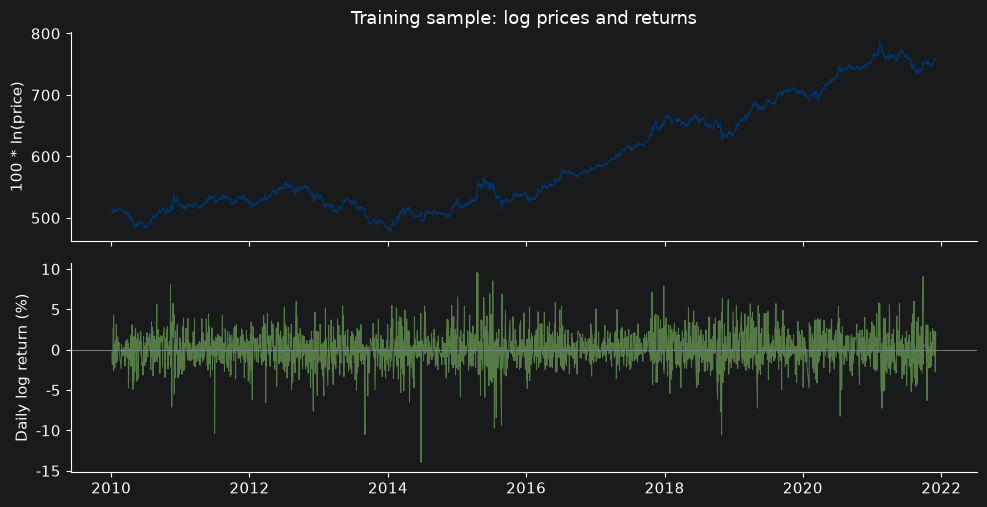

In [4]:
# 上图看长期走势，下图看收益率中心与波动；此处只使用训练期。
fig, axes = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
axes[0].plot(z_train.index, z_train, color="#003366", lw=1)
axes[0].set_ylabel("100 * ln(price)")
axes[0].set_title("Training sample: log prices and returns")
axes[1].plot(train.index, train, color="#557a45", lw=0.7)
axes[1].axhline(0, color="gray", lw=0.7)
axes[1].set_ylabel("Daily log return (%)")
fig.tight_layout()
plt.show()

## 2. ADF、ACF 与 PACF

### ADF：确定建模序列

先比较训练期的对数价格和收益率。ADF 的原假设 $H_0$ 是序列存在单位根；以下以 5% 为显著性水平。`p_value < 0.05` 时拒绝原假设，否则不拒绝。**不拒绝不等于证明存在单位根**；拒绝单位根也不能证明序列独立、正态或方差恒定。

下方调用 `adfuller(series, regression="c", autolag="AIC")`：

- `series`：待检验的一维训练序列。
- `regression="c"`：检验回归包含常数；`"ct"` 还包含线性趋势。应结合序列图和经济含义设定，不为得到小 p 值而反复尝试。
- `autolag="AIC"`：在允许范围内用 AIC 选择检验回归中的差分滞后阶数，用于处理序列相关；**这不是在选择 ARIMA 的 p**。

**结果阅读：**`ADF` 为检验统计量，`p_value` 为 p 值，`Lags` 为所选滞后阶数，`N_obs` 为检验有效样本数。`N_obs` 可能小于输入序列长度，因为检验需要构造滞后项。p 值显示为 0 时应写“极小”，不把它理解为精确的零概率。

判断后再决定输入序列：本实验对收益率演示 `d=0`，对未差分的对数价格演示 `d=1`。差分阶数要结合检验设定和序列特征判断，不能只根据一次检验机械决定。

In [5]:
# 对两个训练序列采用相同检验设定，便于先比较其单位根检验结果。
rows = []
for name, series in {"Log price z": z_train, "Log return r": train}.items():
    # "c" 含常数；AIC 选择的是 ADF 检验的差分滞后阶数，不是 AR 阶数。
    result = adfuller(series, regression="c", autolag="AIC")
    # result[:4] 依次为统计量、p 值、所选滞后阶数、有效样本数。
    rows.append([name, "c", *result[:4]])
adf_table = pd.DataFrame(rows, columns=[
    "Series", "Deterministic", "ADF", "p_value", "Lags", "N_obs"
]).set_index("Series")
display(adf_table)

,Deterministic,ADF,p_value,Lags,N_obs
Series,,,,,
Log price z,c,0.502187,0.984939,0,2890
Log return r,c,-39.093390,0.000000,1,2888


### ACF/PACF：提出候选模型

**ACF（自相关函数）**描述序列与自身各阶滞后值的相关性；**PACF（偏自相关函数）**控制中间滞后的线性影响后，衡量当前值与某一滞后值的直接线性关系。横轴的 1 阶表示前一个交易观测，不一定是前一个自然日。

对满足相应平稳性、因果性和可逆性条件的总体模型，AR(p) 的 PACF 在 p 阶后截尾，MA(q) 的 ACF 在 q 阶后截尾；ARMA 通常两者都拖尾。这些规律用于提出少量候选，实际样本图不会总是整齐截尾。

下方 `lags=20` 画前 20 阶，`zero=False` 省略恒为 1 的第 0 阶；PACF 的 `method="ywm"` 指定一种 Yule-Walker 估计方式，通常可先保持不变。未指定 `alpha` 时使用默认 95% 参考区间：ACF 默认采用 Bartlett 近似，PACF 使用另一种近似标准误，二者带宽不必相同。

**读图顺序：**先看低阶是否有明显相关，再看随滞后增加怎样变化，最后提出待估计的候选模型。参考区间针对各阶的近似判断，不能把偶然越界的柱数直接当作阶数，也不是对整张图的联合检验。这里为看清较弱相关将纵轴设为 ±0.12；更换样本后若柱线超出范围，应调整或删除 `set_ylim`。

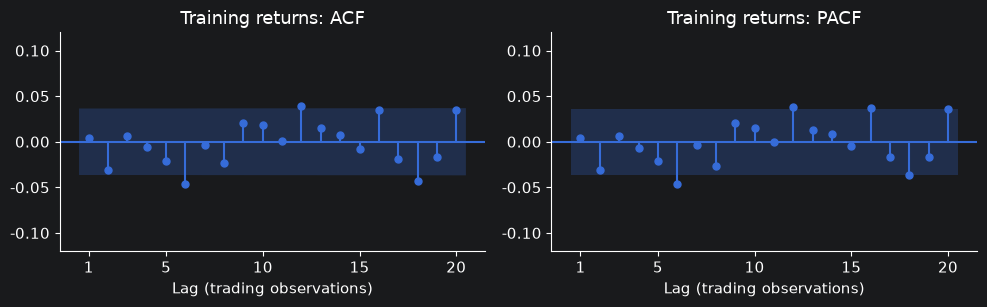

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
# ACF 看各阶相关；PACF 控制中间滞后的线性影响后再看相关。
plot_acf(train, lags=20, zero=False, ax=axes[0], title="Training returns: ACF")
plot_pacf(train, lags=20, zero=False, method="ywm", ax=axes[1], title="Training returns: PACF")
for ax in axes:
    ax.set_xlabel("Lag (trading observations)")
    ax.set_xticks([1, 5, 10, 15, 20])
    ax.set_ylim(-0.12, 0.12)  # 放大纵轴，便于观察本样本中较弱的相关。
fig.tight_layout()
plt.show()

### 作答区 1：数据与平稳性判断

自选训练期内的一个连续区间，至少包含 500 个有效收益率，且不包含最后 20 个交易日。报告日期范围和样本量，绘制对数价格与对数收益率图。

对这两个序列分别进行 ADF 检验，报告确定性项设置、ADF 统计量、p 值与所选滞后阶数。为收益率绘制 ACF、PACF 图，结合图形和检验说明适合对哪个序列采用 d=0 建模。说明 ADF 检验结论的范围。

在下方编写代码，首行添加 `--run` 后运行。本题变量不传入其他题。

In [7]:
%%practice q1
# 从 train、z_train 选择同一段连续训练日期，避免误用留出期。
# 依次整理样本信息、时间图、ADF 表和收益率 ACF/PACF，再写判断依据。
# ADF 的趋势设置须与序列特征相符；不要把检验的 Lags 当成 AR 阶数。
# 使用 display(...) 显示表格、plt.show() 显示图形；自行选择区间和参数。


Exercise q1 skipped. Add --run to the first line when ready.


**第 1 题分析：**

可依次说明：所选区间与样本量；ADF 的确定性项与检验依据；ACF/PACF 特征；适合建模的序列及判断局限。

在此填写自己的结果与分析。

## 3. 同一接口拟合 AR、MA 与 ARMA

`ARIMA` 是本课统一使用的模型类。`order=(p,d,q)` 指定 AR 阶数、差分阶数和 MA 阶数；类名叫 ARIMA，并不表示每次都必须差分。

| 模型 | `order=(p,d,q)` | 本次输入 |
|---|---|---|
| AR(p) | `(p,0,0)` | 训练收益率 |
| MA(q) | `(0,0,q)` | 训练收益率 |
| ARMA(p,q) | `(p,0,q)` | 训练收益率 |
| ARIMA(p,1,q) | `(p,1,q)` | 未手工差分的训练对数价格 |

先以 AR(1) 为例，分两步调用：`ARIMA(...)` 创建模型对象，说明“准备估计什么”；`.fit(...)` 用训练数据估计参数，返回可用于诊断和预测的结果对象。`ar_model` 是前者，`ar_fit` 是后者。

- `trend="c"`：在这里 `d=0` 的模型中允许非零长期均值。
- `method_kwargs={"maxiter": 300}`：允许优化算法最多迭代 300 次；这是计算设置，不是模型阶数，也不保证一定收敛。
- `reset_index(drop=True)`：用连续的交易观测编号输入模型，避免把交易日期误当作等间隔自然日。它不打乱样本；原日期仍保留在 `train` 中，预测后再恢复日期对应。

先运行下方 AR(1)，结合随后的参数说明读表，再运行 MA(1) 和 ARMA(1,1)。

In [8]:
y = train.reset_index(drop=True)  # 模型使用连续编号，原日期仍保留在 train 中。
# 创建模型尚未估计参数：(1,0,0) 是含非零长期均值的 AR(1)。
ar_model = ARIMA(y, order=(1, 0, 0), trend="c")
# fit 返回估计结果；maxiter 限制优化次数，不改变 AR 阶数。
ar_fit = ar_model.fit(method_kwargs={"maxiter": 300})
# 参数表先看 Estimate 的符号和大小，再看 p_value；后面还要做诊断。
display(pd.DataFrame({"Estimate": ar_fit.params, "p_value": ar_fit.pvalues}))
# 如需完整报告，可运行 print(ar_fit.summary())。

,Estimate,p_value
const,0.084819,0.024619
ar.L1,0.003873,0.812123
sigma2,4.052514,0.000000


### 把输出参数对应到模型方程

这里 `ARIMA(..., order=(1,0,0), trend="c")` 的 AR(1) 可以写为：

$$
r_t-\mu=\phi(r_{t-1}-\mu)+\varepsilon_t.
$$

| 输出名称 | 统计含义 | 阅读提示 |
|---|---|---|
| `const` | 长期均值 $\mu$ | 收益率已乘 100，按相应收益率单位解释 |
| `ar.L1` | 一阶 AR 系数 $\phi$ | 衡量偏离均值的部分如何随上一期变化 |
| `sigma2` | 误差项方差 $\sigma^2$ | 是方差，不是标准差；通常也不等于序列的总方差 |
| `p_value` | 对单个参数为零的检验 p 值 | 不能替代整体模型诊断或预测评价 |

若教材写成 $r_t=c+\phi r_{t-1}+\varepsilon_t$，递推截距是 $c=(1-\phi)\mu$，**不要把本接口的 `const` 直接当作该截距**。参数名称 `ar.L1` 中的 `L1` 表示滞后一期。

MA(1) 的对应方程为 $r_t=\mu+\varepsilon_t+\theta\varepsilon_{t-1}$，`ma.L1` 对应 $\theta$。statsmodels 的 MA 项采用加号约定，解释时要与教材的符号一致。MA 的滞后对象是误差项，模型会在估计过程中处理这些不可直接观测的项，无需先手工提供残差；`rolling().mean()` 则是移动平均平滑，不是 MA 模型。

**继续看代码：**下方只改变 `order` 就能拟合 MA 与 ARMA。每个结果对象保存在 `fits` 中，后续诊断和预测直接复用，避免重复估计。

In [9]:
# 只改变 order 即可拟合 MA 和 ARMA；每个模型拟合一次，后续直接复用。
# (0,0,1) 保留一阶 MA 项；(1,0,1) 同时保留一阶 AR 与 MA 项。
ma_fit = ARIMA(y, order=(0, 0, 1), trend="c").fit(method_kwargs={"maxiter": 300})
arma_fit = ARIMA(y, order=(1, 0, 1), trend="c").fit(method_kwargs={"maxiter": 300})
# 字典把模型名对应到结果对象；orders 保存相同模型名下的阶数。
fits = {"AR(1)": ar_fit, "MA(1)": ma_fit, "ARMA(1,1)": arma_fit}
orders = {"AR(1)": (1, 0, 0), "MA(1)": (0, 0, 1), "ARMA(1,1)": (1, 0, 1)}

# 用同一训练样本比较信息准则，并保留优化算法的收敛状态。
rows = []
for name, fit in fits.items():
    rows.append([name, str(orders[name]), fit.aic, fit.bic, fit.mle_retvals["converged"]])
comparison = pd.DataFrame(rows, columns=["Model", "order", "AIC", "BIC", "Converged"]).set_index("Model")
display(comparison.sort_values("BIC"))

# 只比较已收敛且 BIC 有限的模型；不使用留出期结果选择模型。
eligible = comparison.loc[comparison["Converged"] & np.isfinite(comparison["BIC"])]
if eligible.empty:
    raise RuntimeError("No eligible model converged. Check the data or reduce model orders.")
# idxmin 返回最小值所在的模型名；暂选之后仍需残差诊断。
selected_name = eligible["BIC"].idxmin()
selected_fit = fits[selected_name]
print("Candidate selected by training BIC:", selected_name)

,order,AIC,BIC,Converged
Model,,,,
MA(1),"(0, 0, 1)",12251.513113,12269.420148,True
AR(1),"(1, 0, 0)",12251.515946,12269.422981,True
"ARMA(1,1)","(1, 0, 1)",12251.542562,12275.418609,True


Candidate selected by training BIC: MA(1)


### 信息准则只能完成候选比较

`comparison` 的每行是一个模型，`AIC`、`BIC` 越小，表示相应准则下在拟合与复杂度之间的取舍更优；它们不是准确率或预测误差。`Converged=True` 表示优化算法报告收敛，仍需检查模型是否合理。

比较按三步阅读：

1. **先查收敛。**代码只保留已收敛、BIC 为有限数值的候选。
2. **再查可比性。**本表使用相同的训练收益率、样本区间、`d=0` 和确定性项设置；不将不同尺度或不同差分处理的模型直接混排。
3. **最后看差距。**`idxmin()` 取最小 BIC 对应的模型名，`selected_fit` 保存这个候选的估计结果。若两个值很接近，只能说此准则下差别很小，不能宣布其中一个明显更好。

本例 AR(1) 与 MA(1) 的指标非常接近。暂选之后仍要检查残差和样本外表现，也不能根据留出期结果反复调阶。默认设置约束 AR 部分平稳、MA 部分可逆；对含差分模型，这不表示原水平序列平稳。若出现 `ConvergenceWarning`，检查数据、阶数和参数，不通过关闭所有警告来掩盖问题。

### 作答区 2：AR、MA 与 ARMA 的拟合比较

保持基础示例的训练样本和收益率单位不变，自选至少三个候选模型，覆盖 AR、MA、ARMA，至少两个阶数不同于基础示例。建议 p、q 均不超过 3。

用 ARIMA 接口拟合，列出 order、主要参数、AIC、BIC 和是否收敛。依据事先选定的信息准则确定一个候选模型，解释 const、ar.L1 或 ma.L1 的含义。说明 MA 模型与滚动均值的区别。

在下方编写代码，首行添加 `--run` 后运行。本题变量不传入其他题。

In [10]:
%%practice q2
# 先列出自己的候选 order，覆盖 AR、MA、ARMA；每个模型在本题内重新拟合。
# 保持训练区间、输入尺度与 trend 一致，汇总参数、AIC/BIC 和收敛状态。
# 可参考基础示例的“创建模型 → fit → 读取结果”，不要直接复制其全部阶数。
# 用 train 建模，暂不使用 test；解释参数时对照本接口的模型方程。


Exercise q2 skipped. Add --run to the first line when ready.


**第 2 题分析：**

可依次说明：候选阶数与参数含义；收敛情况；事先采用的信息准则及比较差距；暂选模型与需要进一步检查的问题。

在此填写自己的结果与分析。

## 4. 残差诊断

选出候选模型后，检查它是否遗漏了可解释的线性关系。`selected_fit.resid` 给出样本内的一步预测残差，即训练实际值减去基于此前信息的一步预测值。它与后文留出期的多步预测误差不同。

下方先画残差时间图和 ACF，再调用 `acorr_ljungbox`：

- `lags=[10,20]`：分别联合检验前 10 阶、前 20 阶残差自相关系数是否都为零，**不是只检查第 10 阶与第 20 阶**。
- `model_df=p+q`：按已估计的 ARMA 系数个数修正自由度。检验至 m 阶时，自由度为 $m-p-q$，所以所选 m 必须大于 p+q。
- 输出 `lb_stat` 是 Ljung-Box 统计量，`lb_pvalue` 是对应 p 值，行索引表示检验覆盖的最大滞后阶数。

**结果阅读：**以 5% 为水平，p 值小于 0.05 提示仍有未解释的线性相关，应重新检查候选设定。10 阶未拒绝而 20 阶拒绝并不矛盾，因为联合检查的范围不同，应同时报告。未拒绝不能证明残差独立、正态或方差恒定；波动是否集中出现还要结合时间图观察。

若诊断不理想，应把问题写入结论，并仅在训练期内考虑修改模型。本例继续演示预测操作，并不表示暂选模型已通过全部检查。修改样本后，残差 ACF 的纵轴范围也可能需要调整。

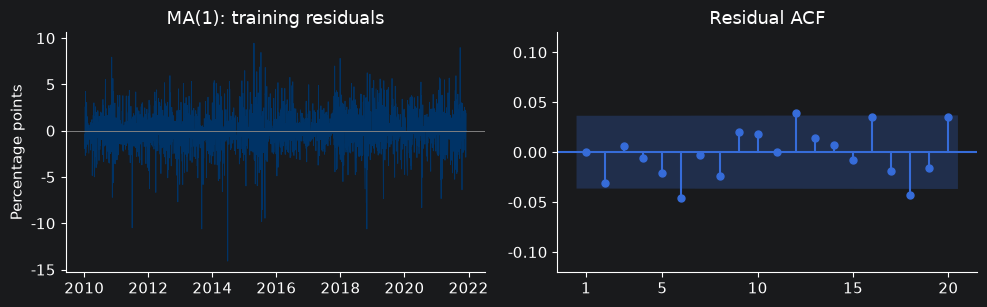

,lb_stat,lb_pvalue
10,14.216051,0.114845
20,33.945455,0.018652


In [11]:
# 从暂选模型取得阶数，用 p+q 设置 Ljung-Box 检验的自由度修正。
p, d, q = orders[selected_name]
# 除去似然计算明确舍弃的初始化部分；本例 d=0 通常为 0。
burn = int(selected_fit.loglikelihood_burn)
# 残差数值与训练日期同时截去 burn 项，保持逐期一一对应。
resid = pd.Series(np.asarray(selected_fit.resid)[burn:], index=train.index[burn:], name="Residual")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(resid.index, resid, lw=0.6, color="#003366")
axes[0].axhline(0, color="gray", lw=0.7)
axes[0].set_title(f"{selected_name}: training residuals")
axes[0].set_ylabel("Percentage points")
plot_acf(resid, lags=20, zero=False, ax=axes[1], title="Residual ACF")
axes[1].set_xticks([1, 5, 10, 15, 20])
axes[1].set_ylim(-0.12, 0.12)
fig.tight_layout()
plt.show()
# 两行分别联合检验前 10 阶和前 20 阶；看 lb_pvalue，不只看统计量。
lb_table = acorr_ljungbox(resid, lags=[10, 20], model_df=p + q, return_df=True)
display(lb_table)

### 作答区 3：残差诊断与模型评价

明确写出所检查的一个模型及其阶数，仅使用训练样本重新拟合。绘制残差图与残差 ACF，选择至少两个大于 p+q 的检验滞后阶数，进行 Ljung-Box 检验并设置 model_df=p+q。

报告检验结果，解释原假设及是否拒绝。结合图形说明模型是否仍遗漏线性相关，并说明这些检查能否证明残差独立、正态或方差恒定。

在下方编写代码，首行添加 `--run` 后运行。本题变量不传入其他题。

In [12]:
%%practice q3
# 先写出要检查的 order，并在本题内重新拟合；不能调用上一题新建的模型。
# 残差与日期必须对应，初始化截取可参考基础示例的 burn 处理。
# 自选至少两个大于 p+q 的检验滞后，分别解释它们覆盖的联合检验范围。
# 结合残差时间图、ACF 和检验结果判断，不只寻找一个较大的 p 值。


Exercise q3 skipped. Add --run to the first line when ready.


**第 3 题分析：**

可依次说明：模型阶数与检验滞后范围；各行 p 值及判断；残差图提供的补充信息；本次检查不能证明的性质。

在此填写自己的结果与分析。

## 5. 固定原点的收益率预测

**预测时点固定在训练期末。**从该时点一次性预测未来 `H=20` 个交易观测，中途不加入留出期实际值，也不更新参数。这与每天加入新数据再预测下一天的滚动预测不同。

| 调用或属性 | 得到什么 |
|---|---|
| `selected_fit.get_forecast(steps=H)` | 包含点预测和区间信息的预测结果对象 |
| `prediction.predicted_mean` | H 个预测收益率，按模型的条件均值解释 |
| `prediction.conf_int()` | 默认 `alpha=0.05` 的 95% 预测区间，可显式修改 alpha |
| `fit.forecast(H)` | 直接返回 H 个点预测，适合只比较预测误差时使用 |

模型使用观测编号，留出数据使用日期索引。代码先取预测数值，再与 `test.index` 对应，确保比较的是同一交易日；**日期错位会使误差计算失去意义**。

设留出期误差 $e_h=r_{T+h}-\widehat r_{T+h\mid T}$，评价指标为：

$$
\mathrm{MAE}=\frac{1}{H}\sum_{h=1}^{H}|e_h|,\qquad
\mathrm{RMSE}=\sqrt{\frac{1}{H}\sum_{h=1}^{H}e_h^2}.
$$

下方代码采用“预测减实际”的误差符号，取绝对值或平方后得到相同指标。两者单位均为**百分点**；在同一目标和样本下越小越好，RMSE 对大误差更敏感。

**先比较基准，再解释模型。**零收益率基准每期预测为 0，训练均值基准每期预测为训练样本均值。复杂模型不一定胜过它们。下方展示三个既定候选，但不再根据这 20 个留出结果调阶。预测图的阴影是模型假设下的未来观测区间，不是参数的置信区间；它也未完整考虑参数估计不确定性，厚尾和波动变化可能影响覆盖率。

In [13]:
# 从训练期末一次预测 H 步；本行不读入任何实际留出收益率。
prediction = selected_fit.get_forecast(steps=H)
# 模型返回观测编号，先取数值再配上真实留出日期，避免索引错位。
mean_forecast = pd.Series(np.asarray(prediction.predicted_mean), index=test.index)
# conf_int 默认 alpha=0.05；这里是未来观测的 95% 预测区间。
interval = pd.DataFrame(np.asarray(prediction.conf_int()), index=test.index, columns=["Lower", "Upper"])

forecast_table = pd.DataFrame({"Actual return": test})
for name in eligible.index:
    # 先取数值再按日期赋值，防止整数索引与日期索引错位。
    if name == selected_name:
        forecast_table[name] = mean_forecast
    else:
        forecast_table[name] = np.asarray(fits[name].forecast(H))
# 两个基准都只使用训练期可获得的信息，不使用 test 的均值。
forecast_table["Zero return"] = 0.0
forecast_table["Training mean"] = train.mean()

# axis=0 表示每一行减去同一日期的实际收益率。
errors = forecast_table.drop(columns="Actual return").sub(test, axis=0)
# 每列对应一种方法；对 H 个日期求平均，MAE 和 RMSE 的单位均为百分点。
return_metrics = pd.DataFrame({"MAE": errors.abs().mean(), "RMSE": np.sqrt(errors.pow(2).mean())})
display(return_metrics.rename_axis("Model or benchmark"))
print("MAE and RMSE are measured in percentage points.")

,MAE,RMSE
Model or benchmark,,
AR(1),1.716147,2.219580
MA(1),1.716168,2.219583
"ARMA(1,1)",1.713889,2.215920
Zero return,1.724269,2.225323
Training mean,1.715787,2.219527


MAE and RMSE are measured in percentage points.


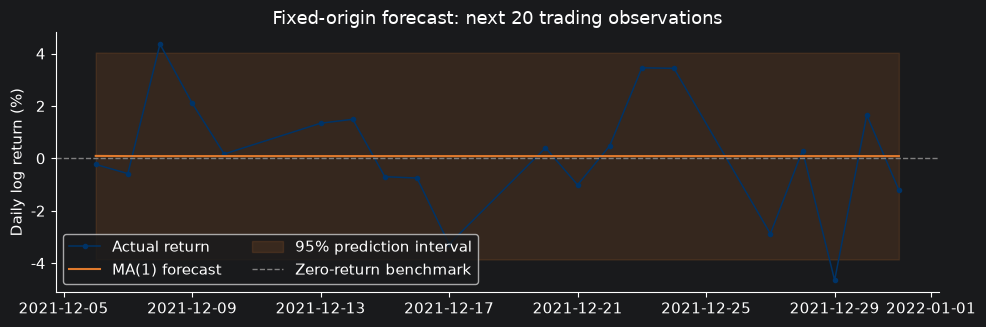

In [14]:
# 将实际值、点预测与区间放在同一时间轴上，观察误差与不确定性。
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(test.index, test, "o-", ms=3, lw=1.1, color="#003366", label="Actual return")
ax.plot(test.index, mean_forecast, color="#E07A2D", lw=1.5, label=f"{selected_name} forecast")
ax.fill_between(test.index, interval["Lower"], interval["Upper"],
                color="#E07A2D", alpha=0.14, label="95% prediction interval")
ax.axhline(0, color="gray", ls="--", lw=1, label="Zero-return benchmark")
ax.set_ylabel("Daily log return (%)")
ax.set_title("Fixed-origin forecast: next 20 trading observations")
ax.legend(loc="best", ncol=2)
fig.tight_layout()
plt.show()

### 作答区 4：收益率预测与基准比较

在训练样本中确定一个模型后，固定参数，一次性预测最后 20 个交易日的收益率。预测过程中不得使用留出期的实际收益率更新模型。

将预测值与实际值按日期对齐，绘制图形，计算 MAE、RMSE。与零收益率预测、训练样本均值预测比较。说明误差的单位、预测方式和结果对该留出期的含义。

在下方编写代码，首行添加 `--run` 后运行。本题变量不传入其他题。

In [15]:
%%practice q4
# 仅用 train 拟合所选模型，再一次性预测 H 步；test 只在预测后用于评价。
# 将预测数值与 test.index 对应，确认预测长度和日期都一致。
# 自行整理模型、零收益率与训练均值基准的误差表，并绘制比较图。
# 说明采用的预测方式、误差单位，以及模型是否优于简单基准。


Exercise q4 skipped. Add --run to the first line when ready.


**第 4 题分析：**

可依次说明：固定原点预测的设置；预测值与日期的对应；模型和基准的 MAE、RMSE 及单位；这段留出样本支持怎样的结论。

在此填写自己的结果与分析。

## 6. ARIMA 拟合对数价格

前面把收益率 `train` 作为输入，设置 `d=0`。现在输入未手工差分的 `z_train`，即 $z_t=100\ln P_t$，由 `order=(1,1,1)` 让模型内部进行一阶差分。差分后 $\Delta z_t=r_t$，因此可以用 ARMA 结构描述这一变化。

**保持输入与 d 一致：**如果已对 z 调用 `.diff()`，又设置 `d=1`，就会再次差分，改变建模对象。本节直接输入 `z_train`。

| 趋势设置 | 含义 | 解释方式 |
|---|---|---|
| `trend="t"` | z 的水平中包含线性时间趋势 | 差分后允许收益率具有非零长期均值，即这里的漂移 |
| `trend="n"` | 不包含上述确定性趋势 | 此处不包含非零平均漂移 |

`d=1` 时不能照搬前面 `trend="c"` 的设置，因为常数项会被一阶差分消去。输出中的 `x1` 通常是时间趋势斜率，差分后对应收益率的长期均值；它不直接等于含 AR 项的递推方程截距。参数标签可能随输入方式而变，应查看实际输出。

ARIMA(1,1,1) 在 z 上与 ARMA(1,1) 在 r 上结构对应，但初始化和似然计算可能不同，不要求估计值逐项完全相同。

**运行后看什么：**先确认收敛，再读参数和误差表。虽然估计时进行了差分，`get_forecast()` 已返回 **z 的水平预测**，无需再次累加。`MAE_z`、`RMSE_z` 在 $100\ln P$ 尺度上计算，与前节收益率误差不能直接比较。最近值基准让未来各期 z 都等于训练期末的 z，相当于价格保持在最后已知值。

In [16]:
# 输入 z 的水平序列；d=1 由模型内部差分，trend="t" 允许平均漂移。
price_fit = ARIMA(z_train.reset_index(drop=True), order=(1, 1, 1), trend="t").fit(
    method_kwargs={"maxiter": 300})
# 先确认算法收敛，再解释参数和使用预测结果。
if not price_fit.mle_retvals["converged"]:
    raise RuntimeError("ARIMA did not converge. Check the model specification.")
display(price_fit.params.to_frame("Estimate"))

# 结果已回到 z=100*ln(P) 的水平尺度，不要再对预测值累计求和。
price_prediction = price_fit.get_forecast(steps=H)
z_mean = pd.Series(np.asarray(price_prediction.predicted_mean), index=z_test.index)
z_interval = pd.DataFrame(np.asarray(price_prediction.conf_int()),
                          index=z_test.index, columns=["Lower", "Upper"])
# 最近值基准在未来每一期都取训练期最后一个 z，不读取留出实际值。
z_forecasts = pd.DataFrame({"ARIMA(1,1,1)": z_mean, "Last-value benchmark": z_train.iloc[-1]})
# 这里评价的是对数价格水平，不能直接与上一节收益率的 RMSE 比大小。
errors_z = z_forecasts.sub(z_test, axis=0)
price_metrics = pd.DataFrame({
    "MAE_z": errors_z.abs().mean(), "RMSE_z": np.sqrt(errors_z.pow(2).mean())
})
display(price_metrics.rename_axis("Model or benchmark"))
print("Errors are measured on the 100 * ln(price) scale, not on the return scale.")

,Estimate
x1,0.084850
ar.L1,-0.765393
ma.L1,0.782421
sigma2,4.049646


,MAE_z,RMSE_z
Model or benchmark,,
"ARIMA(1,1,1)",4.531076,5.147919
Last-value benchmark,5.429544,6.021481


Errors are measured on the 100 * ln(price) scale, not on the return scale.


### 将对数价格预测还原为价格

输入使用了 $z=100\ln P$，因此还原时先除以 100，再取指数：

$$
\widetilde P_{T+h\mid T}=\exp\bigl(\widehat z_{T+h\mid T}/100\bigr).
$$

`np.exp(z_mean / 100)` 完成这一变换。在模型的条件正态对数价格假设下，这条曲线是**价格的条件中位数**，不能直接称为价格条件均值；非线性变换后，均值通常不能直接相互转换。若需要该假设下的价格条件均值，还需预测方差修正，本实验不混用两种点预测。

`z_interval` 的两个端点也分别除以 100 再取指数。指数函数单调递增，因此端点次序保持不变，得到相应的价格预测区间；价格尺度上的区间通常不对称。

**阅读下图：**蓝线是实际价格，橙线是预测中位数，阴影是预测区间，绿色虚线是最近价格基准，竖线表示训练期结束。用图形了解方向、误差与不确定性；是否优于基准还要结合相同尺度的误差指标，不能只凭两条线看起来接近。留出数据只用于评价，不回到建模步骤反复调参。

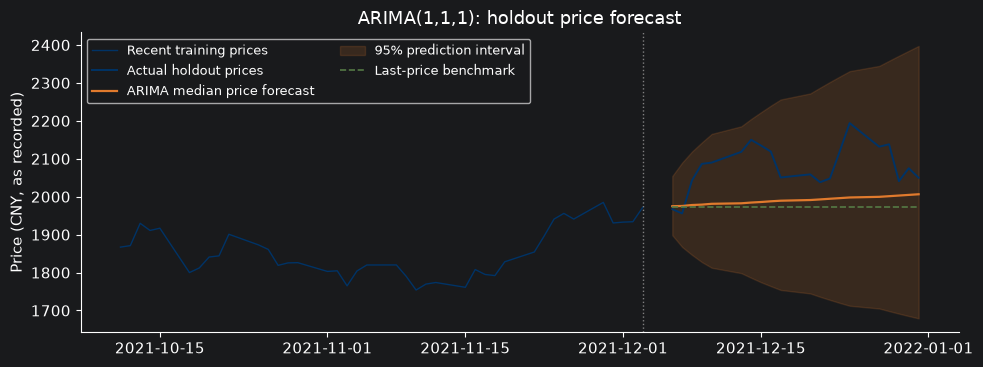

In [17]:
# 撤销原来的乘 100 和取对数；条件正态假设下得到价格条件中位数。
price_median = np.exp(z_mean / 100)
# 单调变换区间两端；还原后的价格区间通常不再关于点预测对称。
price_band = np.exp(z_interval / 100)
actual_price = data.loc[z_test.index, "close"]
fig, ax = plt.subplots(figsize=(10, 3.8))
# 仅补画最近 40 个训练价格提供背景，模型仍使用完整训练期估计。
history = data.loc[:z_train.index[-1], "close"].iloc[-40:]
ax.plot(history.index, history, color="#003366", lw=1, label="Recent training prices")
ax.plot(actual_price.index, actual_price, color="#003366", lw=1.4, label="Actual holdout prices")
ax.plot(price_median.index, price_median, color="#E07A2D", lw=1.6, label="ARIMA median price forecast")
ax.fill_between(price_band.index, price_band["Lower"], price_band["Upper"],
                color="#E07A2D", alpha=0.16, label="95% prediction interval")
ax.hlines(data.loc[z_train.index[-1], "close"], z_test.index[0], z_test.index[-1],
          color="#557a45", ls="--", lw=1.2, label="Last-price benchmark")
ax.axvline(z_train.index[-1], color="gray", ls=":", lw=1)
ax.set_ylabel("Price (CNY, as recorded)")
ax.set_title("ARIMA(1,1,1): holdout price forecast")
ax.legend(loc="upper left", fontsize=9, ncol=2)
fig.tight_layout()
plt.show()

### 作答区 5：ARIMA 与价格预测

以基础示例的训练期对数价格 z=100×ln(P) 为输入，自选一个 p、q 不超过 2 的 ARIMA(p,1,q)，分别使用 trend="n" 和 trend="t" 拟合。保留未手工差分的 z 作为输入。

预测同一组 20 个留出观测，比较两个设定与最近价格基准在 z 尺度上的 MAE、RMSE。绘制一种设定的价格预测曲线及 95% 预测区间，说明指数变换后的预测代表什么，并解释两种 trend 设置的区别。

在下方编写代码，首行添加 `--run` 后运行。本题变量不传入其他题。

In [18]:
%%practice q5
# 自选 p、q，对同一 z_train 分别拟合 trend="n" 和 "t"，保持 d=1。
# z_train 已是对数价格水平，无需先手工差分；两种设定均检查收敛。
# 在 z_test 尺度比较模型与最近值基准；再选择一种设定还原价格和区间。
# get_forecast 已返回 z 的水平预测；不要重复累加，并解释价格点预测的含义。


Exercise q5 skipped. Add --run to the first line when ready.


**第 5 题分析：**

可依次说明：所选阶数；两种 trend 的区别；z 尺度的误差比较；价格点预测与区间的含义；结果的局限。

在此填写自己的结果与分析。

## 7. 综合结论与提交

### 第 6 题：综合分析

结合自己的运行结果，用一段文字说明推荐模型、选择依据、残差诊断、预测表现和适用范围。至少引用一项模型比较结果和一项样本外误差结果，并说明数据口径、20 个留出观测和模型假设对结论的限制。

可以围绕以下问题组织论述：信息准则暂选的模型是否通过残差检查？预测是否优于简单基准？若几个依据不一致，应怎样保留判断的限度？不要把模型的统计拟合或短期预测表现直接解释为可获利的交易策略。

**综合分析：**

在此填写自己的结论。

### 提交前核对

重启内核并从头运行；确认已完成的代码题均显示 `completed`，输出与文字分析相符，再保存 Notebook。`skipped` 说明该题没有执行，`failed` 说明该题尚未运行成功；基础代码全部结束不等于所有题目完成。

需要查阅其他参数时，可从专业接口的官方文档入手：[ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html)、[ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html)、[ACF](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_acf.html)、[PACF](https://www.statsmodels.org/stable/generated/statsmodels.graphics.tsaplots.plot_pacf.html)、[Ljung-Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html)、[预测](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMAResults.get_forecast.html)。